<a href="https://colab.research.google.com/github/ken17102001/AOJ/blob/main/SAN_single20250927.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:

from numpy.core.fromnumeric import shape
import datetime
now = datetime.datetime.now()
time_now=now.strftime('%Y%m%d%H%M%S')
print(time_now)

import torch
import torch.nn as nn
import torch.optim as optim
from torchsummary import summary

# ----------------------------
# PixelShuffle Upsampler
# ----------------------------
class Upsampler(nn.Sequential):
    def __init__(self, scale, n_feats, out_ch=1, bias=True):
        m = []
        if scale in [2, 4, 8]:
            for _ in range(int(scale).bit_length() - 1):
                m += [nn.Conv2d(n_feats, 4 * n_feats, 3, 1, 1, bias=bias),
                      nn.PixelShuffle(2)]
        elif scale == 3:
            m += [nn.Conv2d(n_feats, 9 * n_feats, 3, 1, 1, bias=bias),
                  nn.PixelShuffle(3)]
        else:
            raise ValueError("scale must be 2, 3, 4, or 8")
        m += [nn.Conv2d(n_feats, out_ch, 3, 1, 1, bias=bias)]
        super().__init__(*m)

# ---------------------------------------
# SOCA: Second-Order Channel Attention (簡略版)
# ---------------------------------------
class SOCA(nn.Module):
    def __init__(self, channels, reduction=16):
        super().__init__()
        mid = max(channels // reduction, 4)
        self.fc1 = nn.Conv2d(channels, mid, kernel_size=1, bias=True)
        self.relu = nn.ReLU(inplace=True)
        self.fc2 = nn.Conv2d(mid, channels, kernel_size=1, bias=True)
        self.sigmoid = nn.Sigmoid()

    def forward(self, x):
        b, c, h, w = x.shape
        y = x.view(b, c, -1)
        cov = torch.bmm(y, y.transpose(1, 2)) / (h * w)  # 共分散近似
        desc = cov.mean(dim=2).view(b, c, 1, 1)
        w = self.fc2(self.relu(self.fc1(desc)))
        w = self.sigmoid(w)
        return x * w

# ---------------------------------------
# Residual Block with SOCA
# ---------------------------------------
class ResidualSOCABlock(nn.Module):
    def __init__(self, channels):
        super().__init__()
        self.conv1 = nn.Conv2d(channels, channels, 3, 1, 1, bias=True)
        self.relu = nn.ReLU(inplace=True)
        self.conv2 = nn.Conv2d(channels, channels, 3, 1, 1, bias=True)
        self.soca = SOCA(channels)

    def forward(self, x):
        res = self.conv1(x)
        res = self.relu(res)
        res = self.conv2(res)
        res = self.soca(res)
        return x + res

# ----------------------
# SAN Model
# ----------------------
class SAN(nn.Module):
    def __init__(self, in_ch=1, out_ch=1, n_feats=64, scale=2, n_blocks=8):
        super().__init__()
        self.head = nn.Conv2d(in_ch, n_feats, 3, 1, 1, bias=True)

        body = [ResidualSOCABlock(n_feats) for _ in range(n_blocks)]
        body += [nn.Conv2d(n_feats, n_feats, 3, 1, 1, bias=True)]
        self.body = nn.Sequential(*body)

        self.upsampler = Upsampler(scale, n_feats, out_ch=out_ch)

    def forward(self, x):
        f0 = self.head(x)
        f = self.body(f0)
        f = f + f0
        out = self.upsampler(f)
        return out

# ----------------------
# 動作確認 & 追加部分
# ----------------------
if __name__ == "__main__":
    device = "cuda" if torch.cuda.is_available() else "cpu"
    model = SAN(in_ch=1, out_ch=1, n_feats=64, scale=2, n_blocks=8).to(device)

    # --- Optimizer ---
    optimizer = optim.Adam(model.parameters(), lr=0.001)

    # --- Summary ---
    input_shape = (1, 32, 32)  # (C,H,W)
    summary(model, input_shape)

    # --- パラメータ名表示 ---
    print("\nSAN_Model parameters:\n", model.state_dict().keys())


20250927081814
----------------------------------------------------------------
        Layer (type)               Output Shape         Param #
            Conv2d-1           [-1, 64, 32, 32]             640
            Conv2d-2           [-1, 64, 32, 32]          36,928
              ReLU-3           [-1, 64, 32, 32]               0
            Conv2d-4           [-1, 64, 32, 32]          36,928
            Conv2d-5              [-1, 4, 1, 1]             260
              ReLU-6              [-1, 4, 1, 1]               0
            Conv2d-7             [-1, 64, 1, 1]             320
           Sigmoid-8             [-1, 64, 1, 1]               0
              SOCA-9           [-1, 64, 32, 32]               0
ResidualSOCABlock-10           [-1, 64, 32, 32]               0
           Conv2d-11           [-1, 64, 32, 32]          36,928
             ReLU-12           [-1, 64, 32, 32]               0
           Conv2d-13           [-1, 64, 32, 32]          36,928
           Conv2d-14    

/tmp/ipython-input-2975130799.py:1: DeprecationWarning: numpy.core.fromnumeric is deprecated and has been renamed to numpy._core.fromnumeric. The numpy._core namespace contains private NumPy internals and its use is discouraged, as NumPy internals can change without warning in any release. In practice, most real-world usage of numpy.core is to access functionality in the public NumPy API. If that is the case, use the public NumPy API. If not, you are using NumPy internals. If you would still like to access an internal attribute, use numpy._core.fromnumeric.shape.
  from numpy.core.fromnumeric import shape


/tmp/ipython-input-1885061213.py:35: FutureWarning: The 'delim_whitespace' keyword in pd.read_csv is deprecated and will be removed in a future version. Use ``sep='\s+'`` instead
  data = pd.read_csv(file,header = None, delim_whitespace = False)
/tmp/ipython-input-1885061213.py:35: FutureWarning: The 'delim_whitespace' keyword in pd.read_csv is deprecated and will be removed in a future version. Use ``sep='\s+'`` instead
  data = pd.read_csv(file,header = None, delim_whitespace = False)
/tmp/ipython-input-1885061213.py:35: FutureWarning: The 'delim_whitespace' keyword in pd.read_csv is deprecated and will be removed in a future version. Use ``sep='\s+'`` instead
  data = pd.read_csv(file,header = None, delim_whitespace = False)
/tmp/ipython-input-1885061213.py:35: FutureWarning: The 'delim_whitespace' keyword in pd.read_csv is deprecated and will be removed in a future version. Use ``sep='\s+'`` instead
  data = pd.read_csv(file,header = None, delim_whitespace = False)


torch.Size([400, 4, 64, 64])
torch.Size([400, 4, 32, 32])
{'epoch': 1, 'Unet_losses': np.float64(14.855341404676437), 'Unet_val_losses': np.float64(3.331350564956665)}
{'epoch': 2, 'Unet_losses': np.float64(1.7763364277780056), 'Unet_val_losses': np.float64(0.8877670764923096)}
{'epoch': 3, 'Unet_losses': np.float64(0.6951947249472141), 'Unet_val_losses': np.float64(0.5861955285072327)}
{'epoch': 4, 'Unet_losses': np.float64(0.48461877182126045), 'Unet_val_losses': np.float64(0.47372350096702576)}
{'epoch': 5, 'Unet_losses': np.float64(0.3979175388813019), 'Unet_val_losses': np.float64(0.36427855491638184)}
{'epoch': 6, 'Unet_losses': np.float64(0.34469414316117764), 'Unet_val_losses': np.float64(0.32539626955986023)}
{'epoch': 7, 'Unet_losses': np.float64(0.30975215695798397), 'Unet_val_losses': np.float64(0.3243434727191925)}
{'epoch': 8, 'Unet_losses': np.float64(0.2854398135095835), 'Unet_val_losses': np.float64(0.24877086281776428)}
{'epoch': 9, 'Unet_losses': np.float64(0.2654264

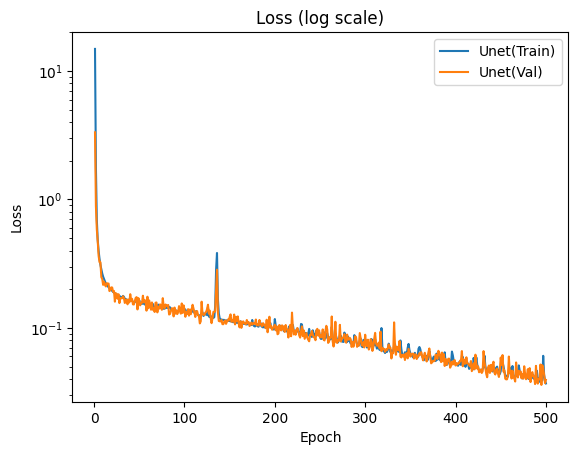

In [ ]:
import argparse
import pathlib
from PIL import Image, ImageOps
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split
import torch
import torch.nn as nn
import torch.nn.functional as F
from matplotlib import pyplot as plt

'''
データ準備
'''
#低解像度画像作成
def LRgenerate(y_train1, y_test1):
  y_train, y_test = torch.tensor(y_train1), torch.tensor(y_test1)
  y_train= y_train.permute(0, 3,1,2)
  y_test= y_test.permute(0, 3,1,2)
  print(y_train.shape)
  LR = nn.MaxPool2d(kernel_size=2, stride=2)
  pooled_train = LR(y_train)
  pooled_test = LR(y_test)
  return pooled_train, pooled_test

import pandas as pd
import numpy as np
from sklearn.metrics import accuracy_score
from sklearn.model_selection import train_test_split
import torch
from torch.utils.data import DataLoader

#データ分割
def Preparation(file):
  data = pd.read_csv(file,header = None, delim_whitespace = False)
  data = data.dropna(how='any', axis = 1)
  all_data = np.array(data)
  train, test = train_test_split(all_data,test_size = 0.2, random_state = None ,shuffle=False)
  train = np.reshape(train,(len(train),64,64,1))
  test = np.reshape(test,(len(test),64,64,1))

  return train,test

#教師データ分割
def Preparation_concat(file1,file2,file3,file4):
  pre_train1 ,pre_test1 = Preparation(file1)
  pre_train2 ,pre_test2 = Preparation(file2)
  pre_train3 ,pre_test3 = Preparation(file3)
  pre_train4 ,pre_test4 = Preparation(file4)
  pre_train_concat=np.concatenate([pre_train1,pre_train2,pre_train3,pre_train4],3)
  pre_test_concat=np.concatenate([pre_test1,pre_test2,pre_test3,pre_test4],3)
  return pre_train_concat,pre_test_concat

y_train,y_test = Preparation_concat('/content/drive/MyDrive/dn500_for_v/p_11.csv',
                                     '/content/drive/MyDrive/dn500_for_v/u_11.csv',
                                     '/content/drive/MyDrive/dn500_for_v/w_11.csv',
                                     '/content/drive/MyDrive/dn500_for_v/v_11.csv')


LR_train,LR_test = LRgenerate(y_train,y_test)

print(LR_train.shape)

nepochs = 500
batch_size = 25
criterion = nn.MSELoss()
puvw = 1
#データセット
train_loader = DataLoader(list(zip(LR_train[:, puvw:puvw+1, :, :],y_train[:,: , :, puvw:puvw+1])),batch_size = batch_size,shuffle = True)
test_loader =DataLoader(list(zip(LR_test[:, puvw:puvw+1, :, :],y_test[:, :, :, puvw:puvw+1])),batch_size = batch_size,shuffle = False)

#学習

'''Training'''
def train_model(n_epoch):
    model.train()

    history = []
    for epoch in range(n_epoch):
        #Train
        Unet_losses = []
        for X, Y in train_loader:
            X = X.float().to(device)
            Y = Y.float().to(device)
            Y = Y.permute(0, 3, 1, 2)
            optimizer.zero_grad()
            y = model(X)
            loss = criterion(Y, y)
            loss.backward()
            optimizer.step()
            Unet_losses.append(loss.item())

        #Validation
        Unet_val_losses = []
        with torch.no_grad():
          for X, Y in test_loader:
              X = X.float().to(device)

              Y = Y.float().to(device)
              Y = Y.permute(0, 3, 1, 2)
              y = model(X)
              Unet_val_losses.append(loss.item())

        info = {
            "epoch": epoch + 1,
            "Unet_losses": np.mean(Unet_losses),
            "Unet_val_losses": np.mean(Unet_val_losses),
        }

        history.append(info)
        print(info)

    history = pd.DataFrame(history)
    return history

history = train_model(n_epoch=nepochs)

'''モデルパラメータ保存'''
torch.save(model.state_dict(), '/content/drive/MyDrive/kanta/weights/SAN_v{0}.pth'.format(time_now))

'''学習曲線'''
def plot_history(history):
    fig, ax = plt.subplots()

    # 損失の推移を描画する
    ax.set_title("Loss (log scale)")
    ax.plot(history["epoch"], history["Unet_losses"], label="Unet(Train)")
    ax.plot(history["epoch"], history["Unet_val_losses"], label="Unet(Val)")
    ax.set_xlabel("Epoch")
    ax.set_ylabel("Loss")
    ax.set_yscale("log")   # 縦軸を対数スケールに変更
    ax.legend()

    plt.show()

plot_history(history)

In [ ]:
LR = np.load('/content/drive/MyDrive/kanta/data/LR20250827024433.npy')

In [ ]:
import argparse
import pathlib
from PIL import Image, ImageOps
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split
import torch
import torch.nn as nn
import torch.nn.functional as F
from matplotlib import pyplot as plt

'''
データ準備
'''

model_from_weight_u_net = model
model_from_weight_u_net .load_state_dict(torch.load('/content/drive/MyDrive/kanta/weights/SAN_u20250927081814.pth', map_location="cpu"))

#低解像度画像作成
def LRgenerate(y_train1, y_test1):
  y_train, y_test = torch.tensor(y_train1), torch.tensor(y_test1)
  y_train= y_train.permute(0, 3,1,2)
  y_test= y_test.permute(0, 3,1,2)
  print(y_train.shape)
  LR = nn.MaxPool2d(kernel_size=2, stride=2)
  pooled_train = LR(y_train)
  pooled_test = LR(y_test)
  return pooled_train, pooled_test

import pandas as pd
import numpy as np
from sklearn.metrics import accuracy_score
from sklearn.model_selection import train_test_split
import torch
from torch.utils.data import DataLoader

#データ分割
def Preparation(file):
  data = pd.read_csv(file,header = None, delim_whitespace = False)
  data = data.dropna(how='any', axis = 1)
  all_data = np.array(data)
  train, test = train_test_split(all_data,test_size = 0.2, random_state = None ,shuffle=False)
  train = np.reshape(train,(len(train),64,64,1))
  test = np.reshape(test,(len(test),64,64,1))

  return train,test

#教師データ分割
def Preparation_concat(file1,file2,file3,file4):
  pre_train1 ,pre_test1 = Preparation(file1)
  pre_train2 ,pre_test2 = Preparation(file2)
  pre_train3 ,pre_test3 = Preparation(file3)
  pre_train4 ,pre_test4 = Preparation(file4)
  pre_train_concat=np.concatenate([pre_train1,pre_train2,pre_train3,pre_train4],3)
  pre_test_concat=np.concatenate([pre_test1,pre_test2,pre_test3,pre_test4],3)
  return pre_train_concat,pre_test_concat

y_train,y_test = Preparation_concat('/content/drive/MyDrive/dn500_for_v/p_11.csv',
                                     '/content/drive/MyDrive/dn500_for_v/u_11.csv',
                                     '/content/drive/MyDrive/dn500_for_v/w_11.csv',
                                     '/content/drive/MyDrive/dn500_for_v/v_11.csv')


LR_train,LR_test = LRgenerate(y_train,y_test)

print(LR_train.shape)
nepochs = 500
batch_size = 25
criterion = nn.MSELoss()
#データセット
train_loader = DataLoader(list(zip(LR_train,y_train)),batch_size = batch_size,shuffle = True)
test_loader =DataLoader(list(zip(LR_test,y_test)),batch_size = batch_size,shuffle = False)

def pred_model(data_loader,puvw):
  Unet_input, Unet_sv_data, Unet_output = [], [], []

  for input_field, output_field in data_loader:
    input_field  = input_field[:, puvw:puvw+1, :, :].float().to(device)
    print(input_field.shape)


    #output_field = output_field.to(device)

    with torch.no_grad():
      gen_output = model(input_field)
      gen_output = gen_output.permute(0, 3, 1, 2)
      #dis_output = Discriminator_pred(x)

    Unet_input.append(input_field)
    Unet_sv_data.append(output_field)
    Unet_output.append(gen_output)

  Unet_input   = torch.cat(Unet_input, dim=0)
  Unet_sv_data = torch.cat(Unet_sv_data, dim=0)
  Unet_output  = torch.cat(Unet_output, dim=0)
  return Unet_input, Unet_sv_data, Unet_output

puvw = 1
model_input, model_sv_data, model_output = pred_model(test_loader,puvw)
model_sv_data = model_sv_data.permute(0, 3, 1, 2)
model_output = model_output.permute(0, 2, 1, 3)
model_sv_data = model_sv_data.cpu().numpy()
model_output = model_output.cpu().numpy()
model_input = model_input.cpu().numpy()
print(model_input.shape)
print(model_sv_data.shape)
print(model_output.shape)

/tmp/ipython-input-2236251566.py:39: FutureWarning: The 'delim_whitespace' keyword in pd.read_csv is deprecated and will be removed in a future version. Use ``sep='\s+'`` instead
  data = pd.read_csv(file,header = None, delim_whitespace = False)
/tmp/ipython-input-2236251566.py:39: FutureWarning: The 'delim_whitespace' keyword in pd.read_csv is deprecated and will be removed in a future version. Use ``sep='\s+'`` instead
  data = pd.read_csv(file,header = None, delim_whitespace = False)
/tmp/ipython-input-2236251566.py:39: FutureWarning: The 'delim_whitespace' keyword in pd.read_csv is deprecated and will be removed in a future version. Use ``sep='\s+'`` instead
  data = pd.read_csv(file,header = None, delim_whitespace = False)
/tmp/ipython-input-2236251566.py:39: FutureWarning: The 'delim_whitespace' keyword in pd.read_csv is deprecated and will be removed in a future version. Use ``sep='\s+'`` instead
  data = pd.read_csv(file,header = None, delim_whitespace = False)


torch.Size([400, 4, 64, 64])
torch.Size([400, 4, 32, 32])
torch.Size([25, 1, 32, 32])
torch.Size([25, 1, 32, 32])
torch.Size([25, 1, 32, 32])
torch.Size([25, 1, 32, 32])
(100, 1, 32, 32)
(100, 4, 64, 64)
(100, 1, 64, 64)


Text(0.5, 1.0, 'p_LR')

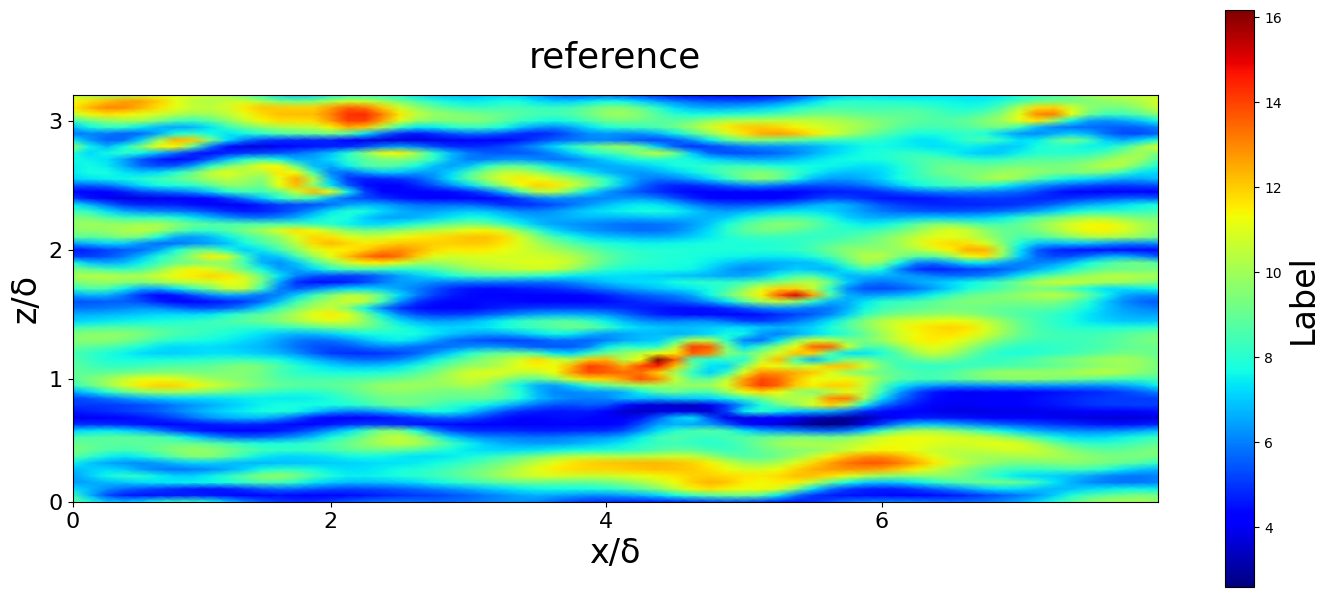

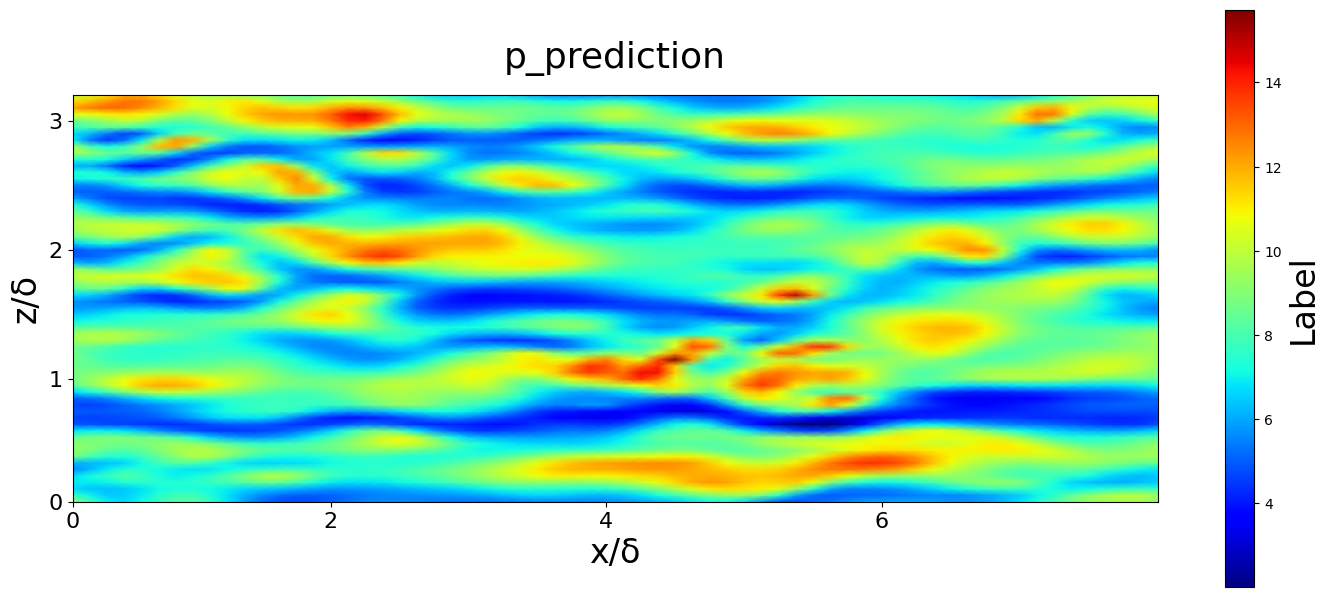

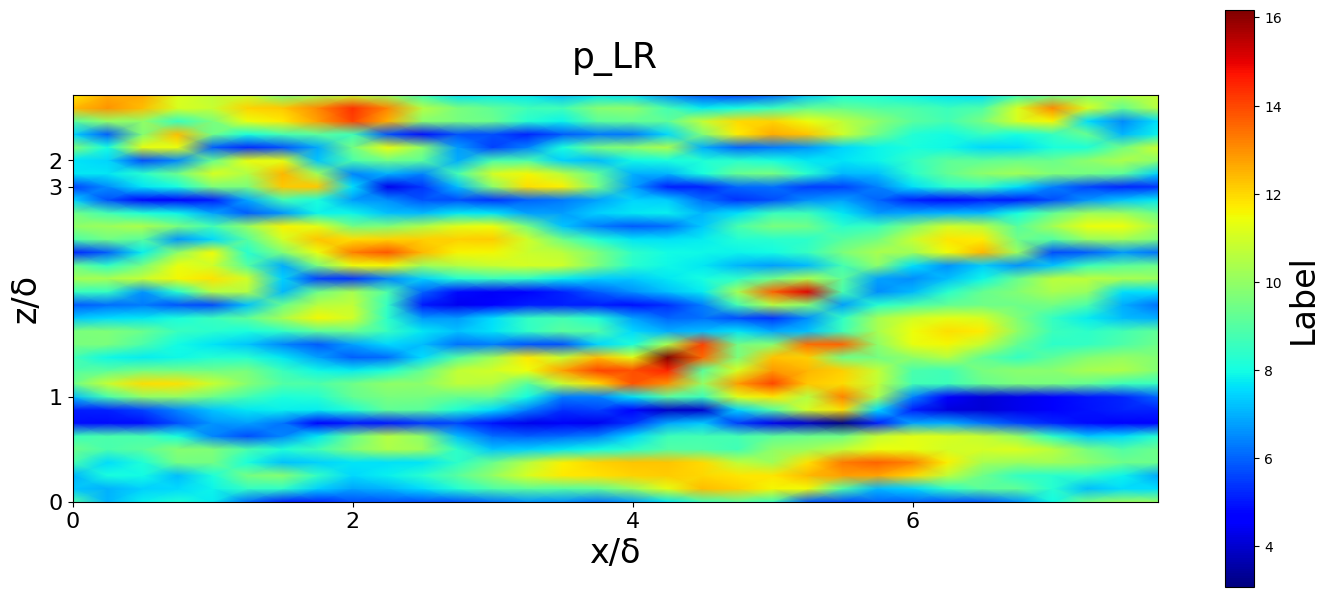

In [ ]:
plt.figure(figsize=(17.5, 7.5)) #分布図の画像サイズを定義
plt.pcolormesh(model_sv_data[13][puvw].T, cmap='jet', shading='gouraud') #カラーマップを作成 カラーマップはjet #変数名をvisu_data[visu_num]に変更
plt.gca().set_aspect(0.375)  #カラーマップ自体のアスペクト比を設定
plt.xticks([0, 15, 31, 47], [ "0", "2", "4", "6"]) #x軸目盛りの指定
plt.yticks([0, 19, 39, 59], [ "0", "1", "2", "3"]) #y軸目盛りの指定
plt.xlabel('x/δ', fontsize=24) #x軸ラベル
plt.ylabel('z/δ', fontsize=24) #y軸ラベル
plt.tick_params(labelsize=16) #メモリのフォントサイズ
pp=plt.colorbar() #カラーバーの表示
pp.set_label("Label",  fontsize=24) #カラーバーにラベルを設定
plt.title("reference", fontsize=26, pad=20)

plt.figure(figsize=(17.5, 7.5)) #分布図の画像サイズを定義
plt.pcolormesh(model_output[13][0], cmap='jet', shading='gouraud') #カラーaマップを作成 カラーマップはjet #変数名をvisu_data[visu_num]に変更
plt.gca().set_aspect(0.375)  #カラーマップ自体のアスペクト比を設定
plt.xticks([0, 15, 31, 47], [ "0", "2", "4", "6"]) #x軸目盛りの指定
plt.yticks([0, 19, 39, 59], [ "0", "1", "2", "3"]) #y軸目盛りの指定
plt.xlabel('x/δ', fontsize=24) #x軸ラベル
plt.ylabel('z/δ', fontsize=24) #y軸ラベル
plt.tick_params(labelsize=16) #メモリのフォントサイズ
pp=plt.colorbar() #カラーバーの表示
pp.set_label("Label",  fontsize=24) #カラーバーにラベルを設定
plt.title("p_prediction", fontsize=26, pad=20)

plt.figure(figsize=(17.5, 7.5)) #分布図の画像サイズを定義
plt.pcolormesh(model_input[13][0].T, cmap='jet', shading='gouraud') #カラーマップを作成 カラーマップはjet #変数名をvisu_data[visu_num]に変更
plt.gca().set_aspect(0.375)  #カラーマップ自体のアスペクト比を設定
plt.xticks([0, 8, 16, 24], [ "0", "2", "4", "6"]) #x軸目盛りの指定
plt.yticks([0, 8, 26, 24], [ "0", "1", "2", "3"]) #y軸目盛りの指定
plt.xlabel('x/δ', fontsize=24) #x軸ラベル
plt.ylabel('z/δ', fontsize=24) #y軸ラベル
plt.tick_params(labelsize=16) #メモリのフォントサイズ
pp=plt.colorbar() #カラーバーの表示
pp.set_label("Label",  fontsize=24) #カラーバーにラベルを設定
plt.title("p_LR", fontsize=26, pad=20)

In [ ]:
np.save('/content/drive/MyDrive/kanta/result/w-HR_pre20250925090246',model_output)

In [ ]:
LR = np.load('/content/drive/MyDrive/kanta/result/HR_pre20250827024433.npy')
HR = np.load('/content/drive/MyDrive/result/FSRCNN/HR20250827024433.npy')
HR_pred = np.load('/content/drive/MyDrive/result/FSRCNN/HR_pre20250827024433.npy')

In [ ]:
pred = np.load('/content/drive/MyDrive/kanta/result/HR_pre20250827024433.npy')
HR = np.load('/content/drive/MyDrive/kanta/data/HR20250827024433.npy')
pred_p = np.load('/content/drive/MyDrive/kanta/result/p-HR_pre20250925041530.npy')
pred_u = np.load('/content/drive/MyDrive/kanta/result/u-HR_pre20250925041530.npy')
pred_w = np.load('/content/drive/MyDrive/kanta/result/w-HR_pre20250925090246.npy')
pred_v = np.load('/content/drive/MyDrive/kanta/result/v-HR_pre20250925073949.npy')
data_list = []
data_list.append(pred_p)
data_list.append(pred_u)
data_list.append(pred_w)
data_list.append(pred_v)
data_list=np.array(data_list)

In [ ]:
data_list=np.array(data_list)

In [ ]:
data_list = np.squeeze(data_list)

In [ ]:
data_list = data_list.transpose(1, 0, 2, 3)

In [ ]:
import numpy as np
from skimage.metrics import peak_signal_noise_ratio as psnr

def PSNR(model_output,model_sv_data):
  PSNR_list = []
  for i in range(4):
    PSNR = []
    for j in range(100):
      pred = model_output[j][i]
      true = model_sv_data[j][i]
      psnr_value = psnr(pred, true, data_range=pred.max() - pred.min())
      print(psnr_value)
      PSNR.append(psnr_value)
    PSNR_list.append(PSNR)
  return PSNR_list






17.1556366757976
14.742161860304773
17.807882870457355
18.641711150037224
15.114955160664334
14.363340203891097
19.158818728255966
14.196547163117303
15.797280403678446
15.779081776103787
16.131659263044757
16.0093995151407
17.554153501829152
18.8782575310338
16.17821676665204
15.741326017725148
13.988806591135752
15.906673410982162
16.815829255908938
17.010710984723882
15.312632663076675
14.436624782332094
16.610844228144455
15.657773375911017
16.935132233020976
16.072192192180506
14.34842423248082
16.215842814185322
15.701930151964635
18.306239790570984
15.51284428024616
14.547066416815841
16.418056596944936
14.974746765983406
14.79689685883643
15.379054117126906
18.871291778124032
15.413502283891148
16.009952837834046
15.260575502896327
16.37380770289419
14.399752744832018
18.24697925691919
15.993860381289466
15.745101123022105
16.577293499403623
15.093065892716993
13.475390474450567
15.161327803529163
16.18662520519577
14.57190078586513
14.794685821267805
20.203013156826618
15.2609

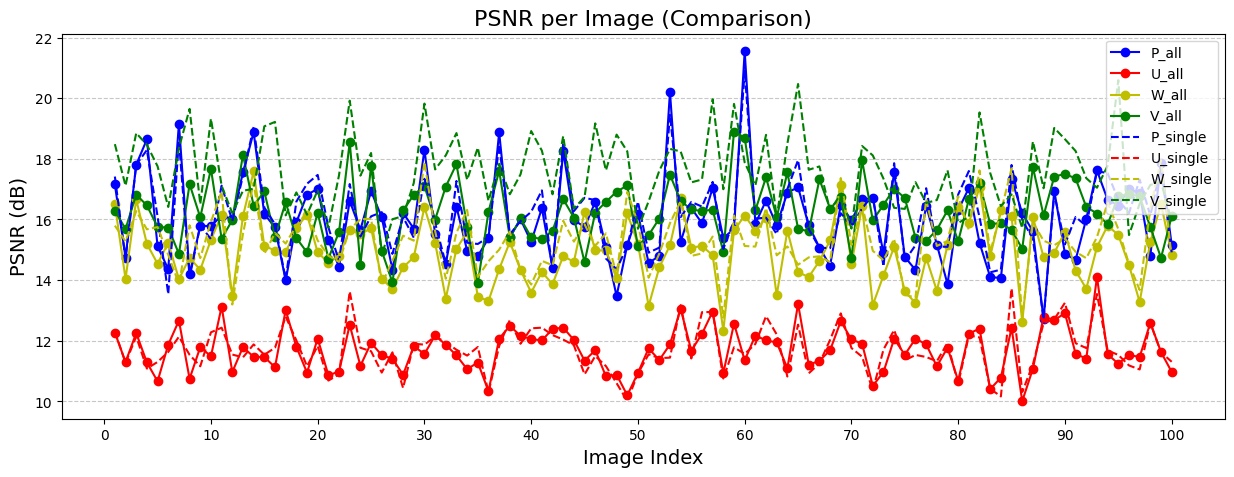

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
PSNR_list= PSNR(pred,HR)
PSNR_list_comp= PSNR(data_list,HR)
# 既存データ
PSNR_p = PSNR_list[0]
PSNR_u = PSNR_list[1]
PSNR_w = PSNR_list[2]
PSNR_v = PSNR_list[3]

# 比較対象データ（例：別の実験結果）
# ここは実際の比較対象リストに置き換えてください
PSNR_p_comp = PSNR_list_comp[0]
PSNR_u_comp = PSNR_list_comp[1]
PSNR_w_comp = PSNR_list_comp[2]
PSNR_v_comp = PSNR_list_comp[3]

# 横軸
x = np.arange(1, len(PSNR_p) + 1)

plt.figure(figsize=(15, 5))

# 元データ（実線）
plt.plot(x, PSNR_p, marker='o', linestyle='-', color='b', label="P_all")
plt.plot(x, PSNR_u, marker='o', linestyle='-', color='r', label="U_all")
plt.plot(x, PSNR_w, marker='o', linestyle='-', color='y', label="W_all")
plt.plot(x, PSNR_v, marker='o', linestyle='-', color='g', label="V_all")

# 比較対象データ（破線、同じ色）
plt.plot(x, PSNR_p_comp, linestyle='--', color='b', label="P_single")
plt.plot(x, PSNR_u_comp, linestyle='--', color='r', label="U_single")
plt.plot(x, PSNR_w_comp, linestyle='--', color='y', label="W_single")
plt.plot(x, PSNR_v_comp, linestyle='--', color='g', label="V_single")

# タイトル・ラベル
plt.title("PSNR per Image (Comparison)", fontsize=16)
plt.xlabel("Image Index", fontsize=14)
plt.ylabel("PSNR (dB)", fontsize=14)
plt.legend(loc="upper right")

# 横軸の間引き
plt.xticks(np.arange(0, len(PSNR_p)+1, 10))

# グリッド
plt.grid(axis='y', linestyle='--', alpha=0.7)

plt.show()

17.1556366757976
14.742161860304773
17.807882870457355
18.641711150037224
15.114955160664334
14.363340203891097
19.158818728255966
14.196547163117303
15.797280403678446
15.779081776103787
16.131659263044757
16.0093995151407
17.554153501829152
18.8782575310338
16.17821676665204
15.741326017725148
13.988806591135752
15.906673410982162
16.815829255908938
17.010710984723882
15.312632663076675
14.436624782332094
16.610844228144455
15.657773375911017
16.935132233020976
16.072192192180506
14.34842423248082
16.215842814185322
15.701930151964635
18.306239790570984
15.51284428024616
14.547066416815841
16.418056596944936
14.974746765983406
14.79689685883643
15.379054117126906
18.871291778124032
15.413502283891148
16.009952837834046
15.260575502896327
16.37380770289419
14.399752744832018
18.24697925691919
15.993860381289466
15.745101123022105
16.577293499403623
15.093065892716993
13.475390474450567
15.161327803529163
16.18662520519577
14.57190078586513
14.794685821267805
20.203013156826618
15.2609

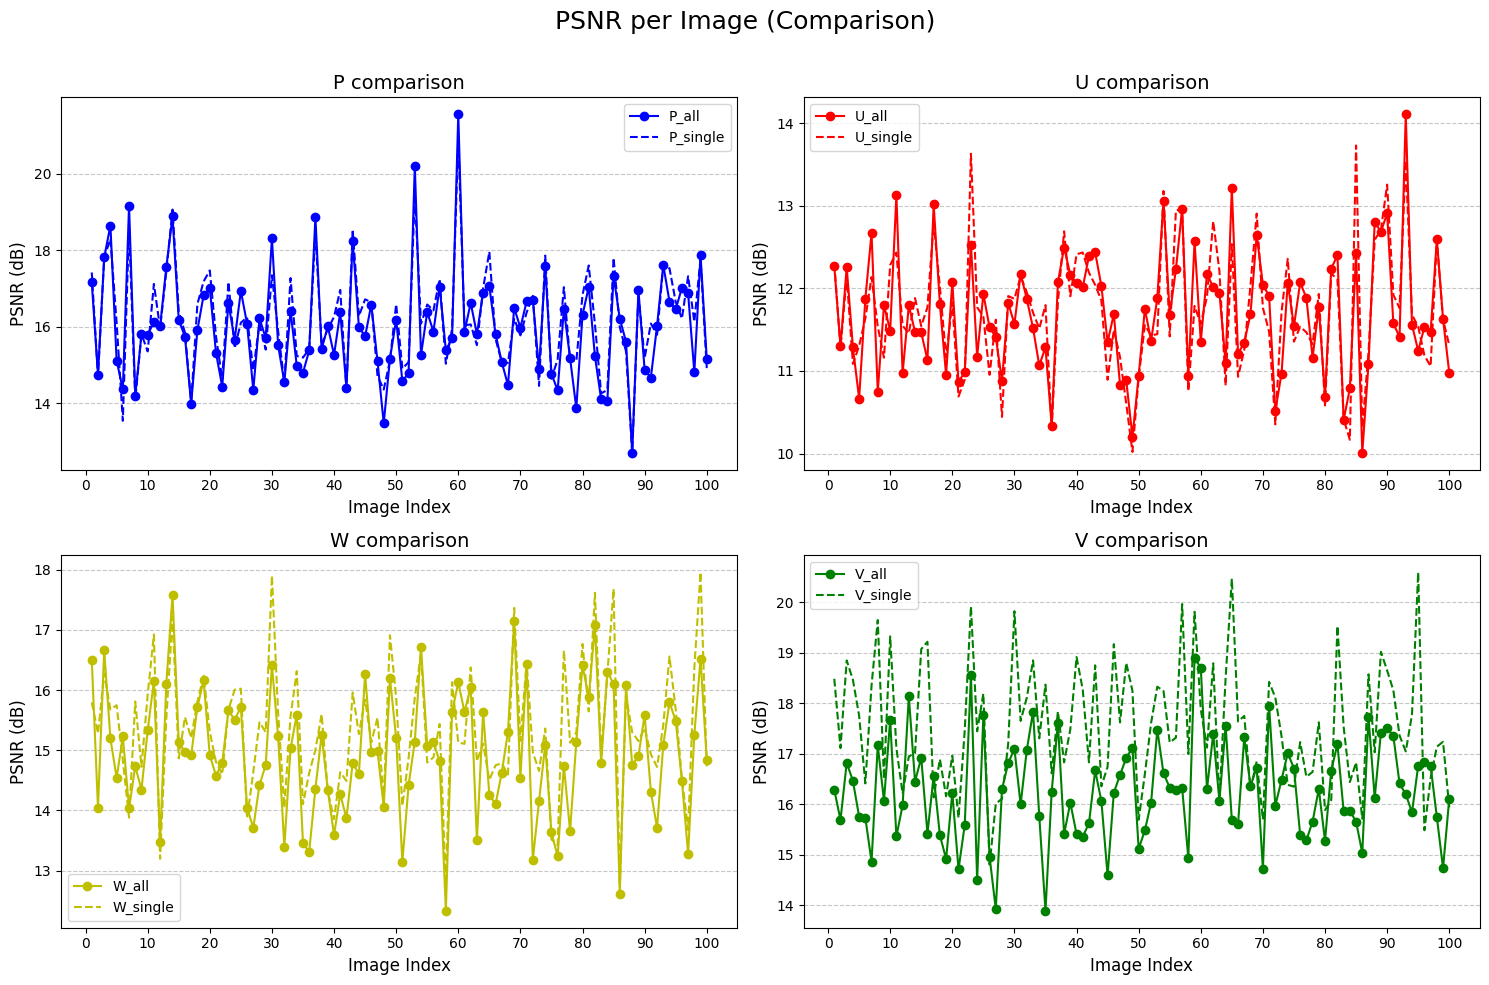

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

PSNR_list = PSNR(pred, HR)
PSNR_list_comp = PSNR(data_list, HR)

# 既存データ
PSNR_p, PSNR_u, PSNR_w, PSNR_v = PSNR_list
# 比較対象データ
PSNR_p_comp, PSNR_u_comp, PSNR_w_comp, PSNR_v_comp = PSNR_list_comp

# 横軸
x = np.arange(1, len(PSNR_p) + 1)

# サブプロット作成
fig, axs = plt.subplots(2, 2, figsize=(15, 10))
fig.suptitle("PSNR per Image (Comparison)", fontsize=18)

# 色とラベルをまとめる
data = [
    (PSNR_p, PSNR_p_comp, "P", "b"),
    (PSNR_u, PSNR_u_comp, "U", "r"),
    (PSNR_w, PSNR_w_comp, "W", "y"),
    (PSNR_v, PSNR_v_comp, "V", "g"),
]

for ax, (d_all, d_comp, name, color) in zip(axs.ravel(), data):
    # 実線 (all)
    ax.plot(x, d_all, marker='o', linestyle='-', color=color, label=f"{name}_all")
    # 破線 (single)
    ax.plot(x, d_comp, linestyle='--', color=color, label=f"{name}_single")

    ax.set_title(f"{name} comparison", fontsize=14)
    ax.set_xlabel("Image Index", fontsize=12)
    ax.set_ylabel("PSNR (dB)", fontsize=12)
    ax.set_xticks(np.arange(0, len(d_all)+1, 10))
    ax.grid(axis='y', linestyle='--', alpha=0.7)
    ax.legend()

plt.tight_layout(rect=[0, 0, 1, 0.97])  # タイトルのため余白を確保
plt.show()